# 05_01 The Law of Large Numbers: Why Averages Settle Down

**Learning objectives**
- State the **weak** and **strong** laws of large numbers and what each one promises (and does not promise).
- Prove the weak law with **Chebyshev's inequality** and read off the **speed**: the typical error of an average shrinks like $\sigma/\sqrt n$.
- Turn the law into a tool: compute **how many observations you need** (Chebyshev, Hoeffding, the Normal rule and the exact Binomial answer), and see why Chebyshev is safe but wasteful.
- Recognise when the law **fails** (no mean: Cauchy; infinite variance: slow convergence) and avoid the **gambler's fallacy**.

**Prerequisites:** [00_02 Expectation and moments](../../module_00_foundations/notebooks/00_02_expectation_moments.ipynb), [01_01 Binomial](../../module_01_discrete/notebooks/01_01_bernoulli_binomial.ipynb), [04_02 Limits and approximations](../../module_04_relationships/notebooks/04_02_limits_and_approximations.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Mean and variance of an average:** for independent $X_1,\dots,X_n$ with mean $\mu$ and variance $\sigma^2$, the sample mean $\bar X_n=\frac1n\sum X_i$ has $E[\bar X_n]=\mu$ and $\mathrm{Var}(\bar X_n)=\sigma^2/n$ (00_02).
- **Chebyshev's inequality:** for any variable with finite variance, $P(|Y-E[Y]|\ge t)\le \mathrm{Var}(Y)/t^2$. No assumption on the shape: that is its strength and its weakness.
- **Convergence in probability:** $Y_n\xrightarrow{P}c$ means $P(|Y_n-c|>\varepsilon)\to0$ for every $\varepsilon>0$.

## 3. Intuition and story

Flip a fair coin 10 times and you may easily see 7 heads (70 %). Flip it 10,000 times and you will see something very close to 50 %. Nobody doubts this, but **why** is it true, and **how close** is "very close"? The Law of Large Numbers (LLN) is the mathematical statement that makes this precise, and it is the reason that

- a casino with thin odds on each bet is almost certain to profit over millions of bets,
- an insurer can price a policy from historical claim frequencies,
- a poll of a few thousand people tells you about millions,
- a Monte Carlo simulation (Module 12) converges to the right answer.

The two things to take away: (1) averages **converge** to the true mean, and (2) they converge at the **square-root speed**: to get 10 times more precise you need **100 times** more data.

## 4. Formal definition

Let $X_1,X_2,\dots$ be independent and identically distributed (iid) with finite mean $\mu=E[X_i]$, and $\bar X_n=\frac1n\sum_{i=1}^nX_i$.

- **Weak LLN:** for every $\varepsilon>0$, $\;P\big(|\bar X_n-\mu|>\varepsilon\big)\to0$ as $n\to\infty$. (Convergence in probability.)
- **Strong LLN (Kolmogorov):** $P\big(\lim_{n\to\infty}\bar X_n=\mu\big)=1$. (Almost-sure convergence: the *whole path* of running averages settles on $\mu$, not just each fixed $n$ in probability.)

**Quantitative versions (finite variance $\sigma^2$)**

| Bound | Statement | Needs |
|---|---|---|
| Chebyshev | $P(\lvert\bar X_n-\mu\rvert\ge\varepsilon)\le\dfrac{\sigma^2}{n\varepsilon^2}$ | finite variance |
| Hoeffding | $P(\lvert\bar X_n-\mu\rvert\ge\varepsilon)\le2\exp\!\Big(-\dfrac{2n\varepsilon^2}{(b-a)^2}\Big)$ | values in $[a,b]$ |
| Normal rule (CLT, next lesson) | $P(\lvert\bar X_n-\mu\rvert\ge\varepsilon)\approx2\Big(1-\Phi\big(\tfrac{\varepsilon\sqrt n}{\sigma}\big)\Big)$ | large $n$ |

**Standard error:** the typical size of $\bar X_n-\mu$ is $\sigma/\sqrt n$.

## 5. Derivations

### 5.1 The weak law from Chebyshev
$\bar X_n$ has mean $\mu$ and variance $\sigma^2/n$. Apply Chebyshev to $Y=\bar X_n$ with $t=\varepsilon$:
$$P(|\bar X_n-\mu|\ge\varepsilon)\le\frac{\mathrm{Var}(\bar X_n)}{\varepsilon^2}=\frac{\sigma^2}{n\varepsilon^2}\xrightarrow[n\to\infty]{}0.$$
**In plain words.** The average has the same centre as one observation but a spread that shrinks with $n$; once the spread is much smaller than $\varepsilon$, being $\varepsilon$ away is nearly impossible.

### 5.2 Why the variance of an average is $\sigma^2/n$
Independence makes variances add: $\mathrm{Var}(\sum X_i)=n\sigma^2$. Dividing by $n$ divides the variance by $n^2$: $\mathrm{Var}(\bar X_n)=n\sigma^2/n^2=\sigma^2/n$. **In plain words.** Each new observation adds some noise, but the *average* divides by $n$, so noise grows like $\sqrt n$ while the sum grows like $n$.

### 5.3 How many observations? (inverting the bound)
Chebyshev says the failure probability is at most $\delta$ once $n\ge\dfrac{\sigma^2}{\delta\,\varepsilon^2}$. Hoeffding gives $n\ge\dfrac{(b-a)^2\ln(2/\delta)}{2\varepsilon^2}$, which grows only like $\ln(1/\delta)$ instead of $1/\delta$: for a tiny failure probability Hoeffding is far cheaper. The Normal rule gives $n\approx\Big(\dfrac{z_{1-\delta/2}\,\sigma}{\varepsilon}\Big)^2$, the tightest (but approximate).

### 5.4 The speed: halving the error costs four times the data
The error scale is $\sigma/\sqrt n$. To make it $k$ times smaller you need $k^2$ times more data. **In plain words.** Early data is cheap and valuable; late data is expensive: going from 1,000 to 4,000 observations only halves the error.

### 5.5 The strong law in one picture
The weak law says: at each *fixed* large $n$, the average is probably near $\mu$. The strong law says more: with probability 1, the single path $\bar X_1,\bar X_2,\dots$ eventually enters the band $\mu\pm\varepsilon$ and **never leaves**. The proof (Kolmogorov, or Etemadi for pairwise independent variables) uses the Borel-Cantelli lemma along a sparse subsequence $n=2^k$ and fills the gaps by monotonicity; we only need the statement here.

### 5.6 Where it fails
If $E|X|=\infty$ the average has no limit. For the Cauchy distribution the average of $n$ iid copies has *exactly the same Cauchy distribution* as a single observation, so averaging does nothing (shown by simulation below).

## 6. Properties and relationships

- **Sum versus average:** the **sum** $S_n$ drifts away from $n\mu$ (its deviation grows like $\sqrt n$); only the **average** (and the relative error $S_n/n$) converges. This is why "the sum has not caught up yet" is not a law of nature (gambler's fallacy).
- **Relative frequency:** with $X_i=\mathbf 1\{\text{event}\}$, $\bar X_n$ is the relative frequency of the event and converges to its probability: this is the frequentist definition of probability.
- **LLN for functions:** if $E|g(X)|<\infty$ then $\frac1n\sum g(X_i)\to E[g(X)]$: the basis of **Monte Carlo integration** (Example 3) and of the method of moments.
- **Relation to the CLT (05_02):** the LLN says *where* the average goes; the CLT describes the *shape of the fluctuations* around that limit.
- **Beyond iid:** the LLN also holds for many dependent sequences (ergodic theorem, Markov chains), which is why MCMC (Module 07) works, but the effective sample size can be much smaller than $n$.

## 7. 2D visuals

### 7.1 Running averages settle on the true mean
Three different parents; five independent paths each. The dashed band is $\mu\pm2\sigma/\sqrt n$: the paths live inside it about 95 % of the time and it shrinks like the square root.

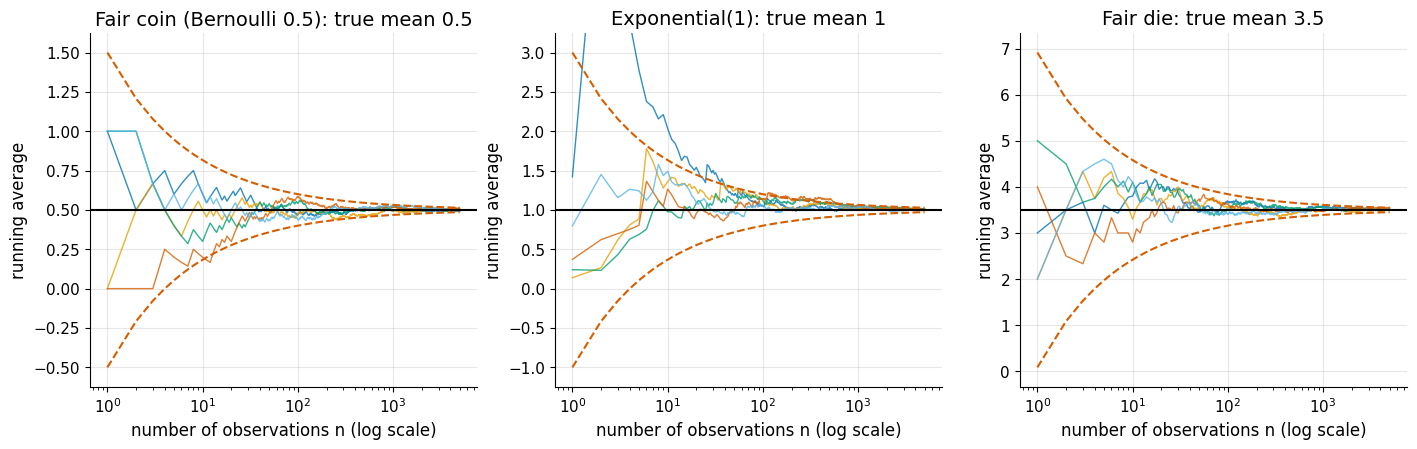

In [2]:
n_max = 5000
n_axis = np.arange(1, n_max + 1)
parents = [("Fair coin (Bernoulli 0.5)", lambda size: rng.binomial(1, 0.5, size), 0.5, 0.5),
           ("Exponential(1)", lambda size: rng.exponential(1.0, size), 1.0, 1.0),
           ("Fair die", lambda size: rng.integers(1, 7, size), 3.5, np.sqrt(35 / 12))]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharex=True)
for ax, (name, sampler, mu, sd) in zip(axes, parents):
    draws = sampler((5, n_max))
    running = np.cumsum(draws, axis=1) / n_axis
    for path in running:
        ax.plot(n_axis, path, linewidth=1, alpha=0.8)
    ax.axhline(mu, color="black", linewidth=1.5)
    ax.plot(n_axis, mu + 2 * sd / np.sqrt(n_axis), "--", color=HIGHLIGHT)
    ax.plot(n_axis, mu - 2 * sd / np.sqrt(n_axis), "--", color=HIGHLIGHT)
    ax.set_xscale("log")
    ax.set_title(f"{name}: true mean {mu:g}")
    ax.set_xlabel("number of observations n (log scale)")
    ax.set_ylabel("running average")
    ax.set_ylim(mu - 1.5 * sd * 1.5, mu + 1.5 * sd * 1.5)
plt.show()

### 7.2 How fast does the probability of a big error vanish?
For Exponential(1) the average of $n$ draws is exactly Gamma($n$, scale $1/n$), so we can compute $P(|\bar X_n-1|>0.1)$ exactly and compare it with the Chebyshev bound, the Normal rule and a simulation.

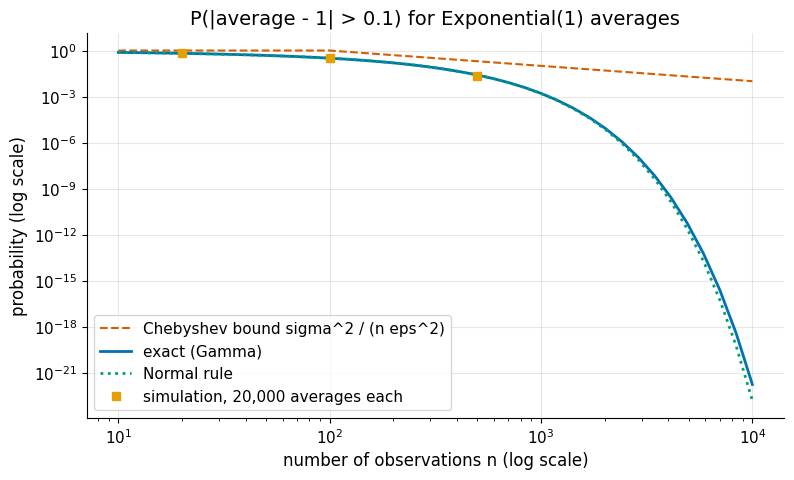

n = 2000: exact 1e-05 Chebyshev 0.04926


In [3]:
eps = 0.1
n_values = np.unique(np.logspace(1, 4, 40).astype(int))
mean_dist = lambda n: stats.gamma(a=n, scale=1 / n)
exact = np.array([mean_dist(n).sf(1 + eps) + mean_dist(n).cdf(1 - eps) for n in n_values])
chebyshev = np.minimum(1, 1 / (n_values * eps**2))
normal_rule = 2 * stats.norm.sf(eps * np.sqrt(n_values))
sim_n = np.array([20, 100, 500, 2000])
sim = [np.mean(np.abs(rng.exponential(1, (20000, n)).mean(axis=1) - 1) > eps) for n in sim_n]
fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogy(n_values, chebyshev, "--", color=HIGHLIGHT, label="Chebyshev bound sigma^2 / (n eps^2)")
ax.semilogy(n_values, exact, color=MAIN, linewidth=2, label="exact (Gamma)")
ax.semilogy(n_values, normal_rule, ":", color=COLORS[2], linewidth=2, label="Normal rule")
ax.semilogy(sim_n, sim, "s", color=SIM, label="simulation, 20,000 averages each")
ax.set_title("P(|average - 1| > 0.1) for Exponential(1) averages")
ax.set_xlabel("number of observations n (log scale)")
ax.set_ylabel("probability (log scale)")
ax.set_xscale("log")
ax.legend()
plt.show()
print("n = 2000: exact", round(float(exact[np.argmin(abs(n_values - 2000))]), 5), "Chebyshev", round(float(chebyshev[np.argmin(abs(n_values - 2000))]), 5))
assert np.all(exact <= chebyshev + 1e-12)

### 7.3 The sum drifts, the average converges
For a fair coin, the *number of heads minus n/2* wanders further and further away (about $\sqrt n$), while the *relative frequency of heads* converges to 0.5. Both statements are true at once.

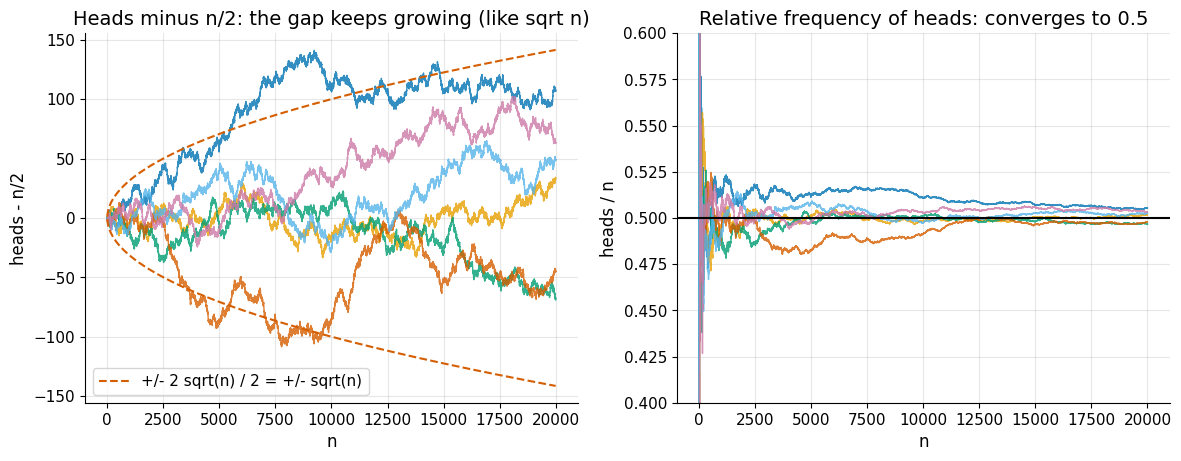

typical |heads - n/2| at n = 20000: [107.  34.  69.  45.  49.  63.]  (sqrt(n)/2 = 70.7 )


In [4]:
n_max = 20000
n_axis = np.arange(1, n_max + 1)
flips = rng.binomial(1, 0.5, (6, n_max))
excess = np.cumsum(flips, axis=1) - n_axis / 2
fig, (ax_sum, ax_avg) = plt.subplots(1, 2, figsize=(14, 4.8))
for path in excess:
    ax_sum.plot(n_axis, path, linewidth=1, alpha=0.8)
ax_sum.plot(n_axis, 2 * 0.5 * np.sqrt(n_axis), "--", color=HIGHLIGHT, label="+/- 2 sqrt(n) / 2 = +/- sqrt(n)")
ax_sum.plot(n_axis, -2 * 0.5 * np.sqrt(n_axis), "--", color=HIGHLIGHT)
ax_sum.set_title("Heads minus n/2: the gap keeps growing (like sqrt n)")
ax_sum.set_xlabel("n")
ax_sum.set_ylabel("heads - n/2")
ax_sum.legend()
for path in excess:
    ax_avg.plot(n_axis, path / n_axis + 0.5, linewidth=1, alpha=0.8)
ax_avg.axhline(0.5, color="black")
ax_avg.set_ylim(0.4, 0.6)
ax_avg.set_title("Relative frequency of heads: converges to 0.5")
ax_avg.set_xlabel("n")
ax_avg.set_ylabel("heads / n")
plt.show()
print("typical |heads - n/2| at n = 20000:", np.round(np.abs(excess[:, -1])), " (sqrt(n)/2 =", round(np.sqrt(n_max) / 2, 1), ")")

### 7.4 When the law fails or is slow
Same experiment with three parents that break the nice conditions. **Cauchy** (no mean): the running average never settles. **Pareto with alpha = 1.5** (mean 3, infinite variance): converges, but erratically and slowly. **Pareto with alpha = 0.8** (infinite mean): the average grows without bound.

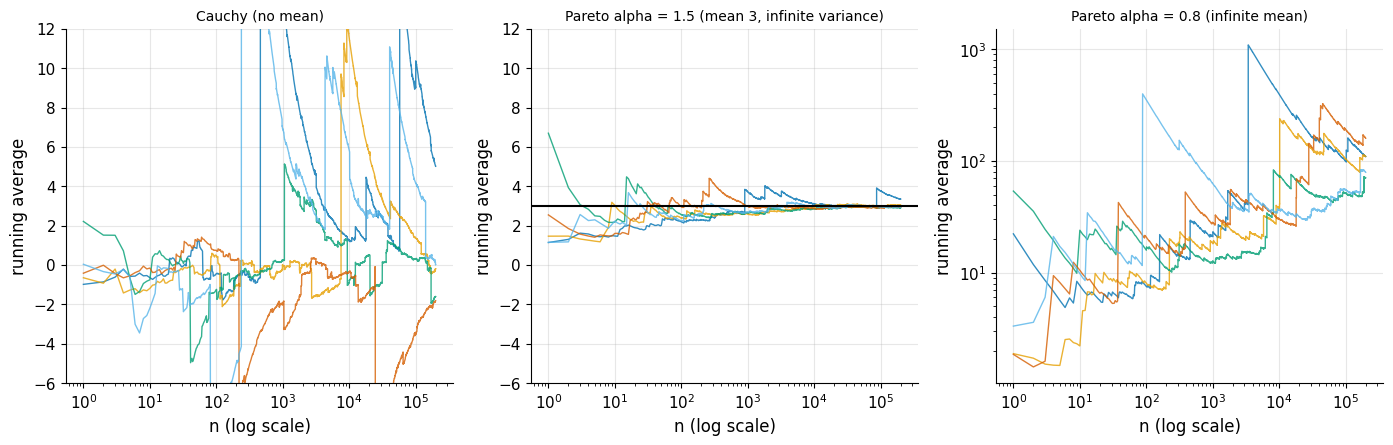

In [5]:
n_max = 200000
n_axis = np.arange(1, n_max + 1)
cases = [("Cauchy (no mean)", lambda size: rng.standard_cauchy(size), None),
         ("Pareto alpha = 1.5 (mean 3, infinite variance)", lambda size: rng.pareto(1.5, size) + 1, 3.0),
         ("Pareto alpha = 0.8 (infinite mean)", lambda size: rng.pareto(0.8, size) + 1, None)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (name, sampler, mu) in zip(axes, cases):
    running = np.cumsum(sampler((5, n_max)), axis=1) / n_axis
    for path in running:
        ax.plot(n_axis, path, linewidth=1, alpha=0.8)
    if mu is not None:
        ax.axhline(mu, color="black", linewidth=1.5)
    ax.set_xscale("log")
    if "0.8" in name:
        ax.set_yscale("log")
    else:
        ax.set_ylim(-6, 12)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("n (log scale)")
    ax.set_ylabel("running average")
plt.show()

### 7.5 How many observations? Four answers to one question
To have $P(|\bar X-\mu|>\varepsilon)\le5\,\%$ for a Bernoulli(0.5) average. Chebyshev is the most expensive, Hoeffding is cheaper, the Normal rule is the cheapest; the exact answer is close to the Normal rule.

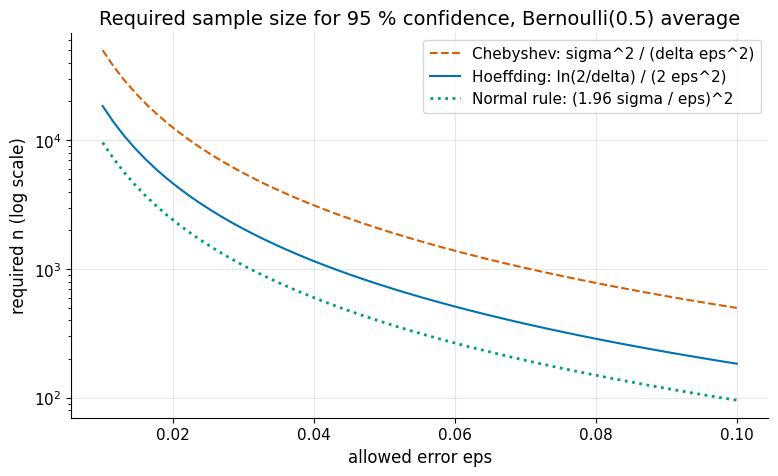

at eps = 0.02:  Chebyshev 12500  Hoeffding 4611  Normal rule 2401


In [6]:
eps_axis = np.linspace(0.01, 0.1, 60)
delta = 0.05
n_chebyshev = 0.25 / (delta * eps_axis**2)
n_hoeffding = np.log(2 / delta) / (2 * eps_axis**2)
n_normal = (stats.norm.isf(delta / 2) * 0.5 / eps_axis) ** 2
fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogy(eps_axis, n_chebyshev, "--", color=HIGHLIGHT, label="Chebyshev: sigma^2 / (delta eps^2)")
ax.semilogy(eps_axis, n_hoeffding, color=MAIN, label="Hoeffding: ln(2/delta) / (2 eps^2)")
ax.semilogy(eps_axis, n_normal, ":", color=COLORS[2], linewidth=2, label="Normal rule: (1.96 sigma / eps)^2")
ax.set_title("Required sample size for 95 % confidence, Bernoulli(0.5) average")
ax.set_xlabel("allowed error eps")
ax.set_ylabel("required n (log scale)")
ax.legend()
plt.show()
print("at eps = 0.02:  Chebyshev", round(float(0.25 / (delta * 0.02**2))), " Hoeffding", round(float(np.log(2 / delta) / (2 * 0.02**2))), " Normal rule", round(float((stats.norm.isf(delta / 2) * 0.5 / 0.02) ** 2)))

## 8. 3D visuals

### 8.1 Static: exact probability of a large error over (n, eps)
$P(|\bar X_n-0.5|>\varepsilon)$ for the fair-coin average, computed exactly from the Binomial. It falls steeply as either $n$ or $\varepsilon$ grows; the ridge near the origin is the 'not enough data yet' zone.

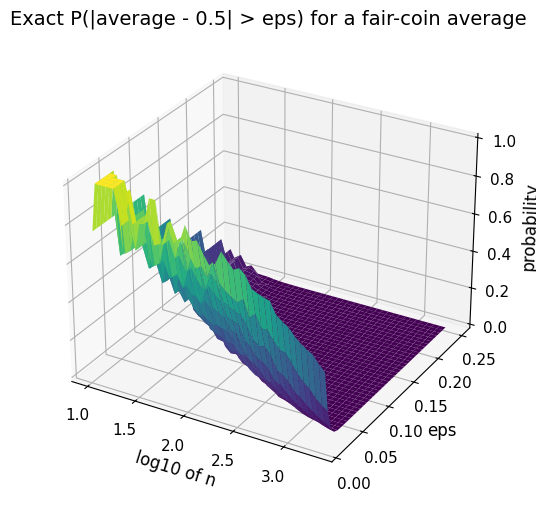

In [7]:
def tail_error_bernoulli(n, eps, p=0.5):
    """Exact P(|mean of n Bernoulli(p) - p| > eps), from the Binomial distribution."""
    lower = stats.binom.cdf(np.ceil(n * (p - eps)) - 1, n, p)         # fewer than n (p - eps) successes
    upper = stats.binom.sf(np.floor(n * (p + eps)), n, p)             # more than n (p + eps) successes
    return lower + upper

n_grid = np.unique(np.round(np.logspace(1, 3.3, 40)).astype(int))
eps_grid = np.linspace(0.01, 0.25, 40)
Z_exact = np.array([[tail_error_bernoulli(n, e) for n in n_grid] for e in eps_grid])
Z_cheb = np.array([[min(1, 0.25 / (n * e**2)) for n in n_grid] for e in eps_grid])
N_g, E_g = np.meshgrid(np.log10(n_grid), eps_grid)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(N_g, E_g, Z_exact, cmap="viridis", edgecolor="none")
ax.set_title("Exact P(|average - 0.5| > eps) for a fair-coin average")
ax.set_xlabel("log10 of n")
ax.set_ylabel("eps")
ax.set_zlabel("probability")
ax.view_init(elev=28, azim=-60)
plt.show()

### 8.2 Static: Chebyshev's bound sits far above the truth
Both surfaces together: the translucent red sheet is the Chebyshev bound (capped at 1), the blue-green surface is the exact probability. The gap between them is the price of not assuming anything about the shape.

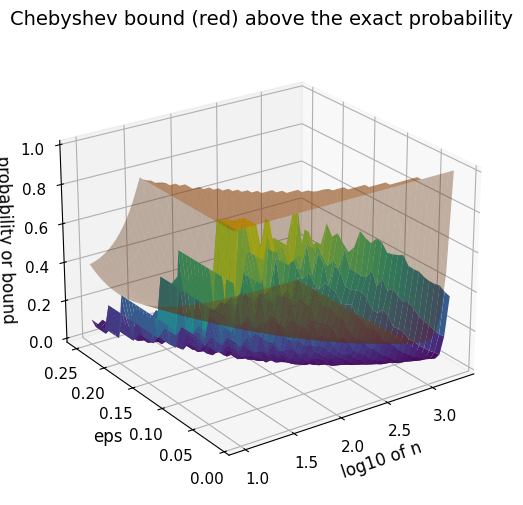

The Chebyshev bound holds at all 1600 grid points; for example at n = 1000, eps = 0.05 the exact probability is 0.00139 while the bound is 0.1


In [8]:
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(N_g, E_g, Z_cheb, color=HIGHLIGHT, alpha=0.35, edgecolor="none")
ax.plot_surface(N_g, E_g, Z_exact, cmap="viridis", edgecolor="none")
ax.set_title("Chebyshev bound (red) above the exact probability")
ax.set_xlabel("log10 of n")
ax.set_ylabel("eps")
ax.set_zlabel("probability or bound")
ax.view_init(elev=24, azim=-125)
plt.show()
assert np.all(Z_exact <= Z_cheb + 1e-12)
print("The Chebyshev bound holds at all", Z_exact.size, "grid points; for example at n = 1000, eps = 0.05 the exact probability is", round(float(tail_error_bernoulli(1000, 0.05)), 5), "while the bound is", round(0.25 / (1000 * 0.05**2), 3))

### 8.3 Static: running averages as 3D paths
Fifteen paths of running averages of Exponential(1): the axes are $\log_{10}n$, the path number and the running average. The funnel toward $\mu=1$ is the LLN.

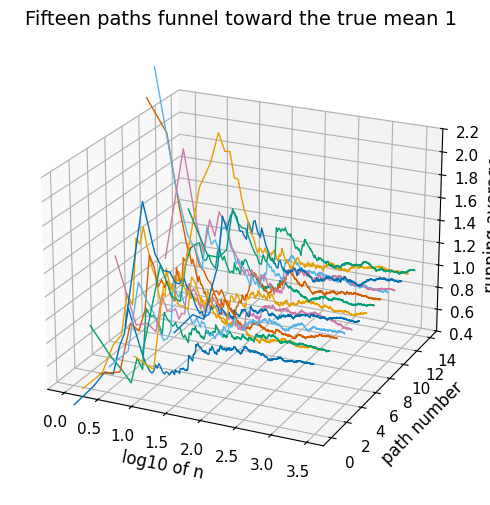

In [9]:
n_axis = np.arange(1, 3001)
running = np.cumsum(rng.exponential(1, (15, 3000)), axis=1) / n_axis
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
for i, path in enumerate(running):
    ax.plot(np.log10(n_axis), np.full(n_axis.size, i), path, linewidth=1)
ax.set_xlabel("log10 of n")
ax.set_ylabel("path number")
ax.set_zlabel("running average")
ax.set_title("Fifteen paths funnel toward the true mean 1")
ax.set_zlim(0.4, 2.2)
ax.view_init(elev=22, azim=-65)
plt.show()

### 8.4 Interactive Plotly version of 8.1
Rotate and hover over the surface to read the exact probability for any $(n,\varepsilon)$.

In [10]:
fig = go.Figure(go.Surface(x=n_grid, y=eps_grid, z=Z_exact, colorscale="Viridis"))
fig.update_layout(title="Exact P(|average - 0.5| > eps), fair coin", width=750, height=550,
                  scene=dict(xaxis_title="n", yaxis_title="eps", zaxis_title="probability", xaxis_type="log"))
fig.show()

## 9. Simulation vs theory

### 9.1 The error of an average is sigma over square root of n
For five parents, simulate many averages of size $n$ and compare their standard deviation with $\sigma/\sqrt n$. On a log-log plot the points must lie on a line of slope $-1/2$.

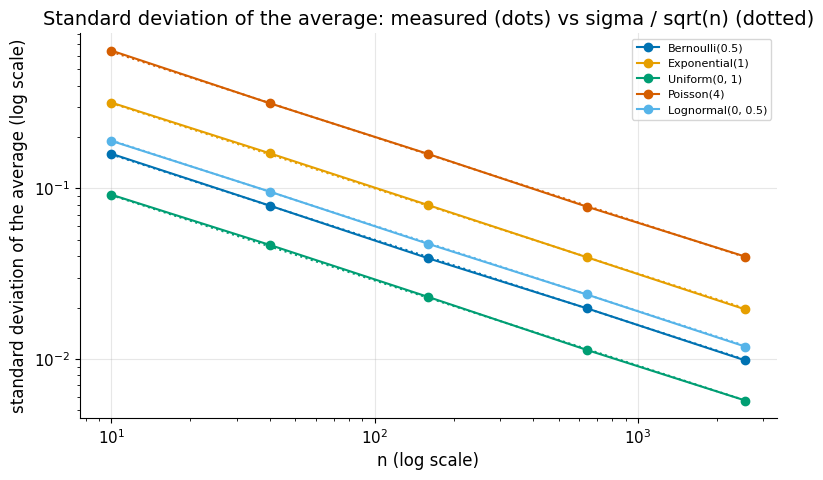

           parent  sigma  log-log slope  max |measured / (sigma/sqrt n) - 1|
   Bernoulli(0.5) 0.5000         -0.503                                0.016
   Exponential(1) 1.0000         -0.504                                0.015
    Uniform(0, 1) 0.2887         -0.503                                0.021
       Poisson(4) 2.0000         -0.502                                0.016
Lognormal(0, 0.5) 0.6039         -0.501                                0.011


In [11]:
specs = [("Bernoulli(0.5)", lambda size: rng.binomial(1, 0.5, size), 0.5),
         ("Exponential(1)", lambda size: rng.exponential(1, size), 1.0),
         ("Uniform(0, 1)", lambda size: rng.uniform(0, 1, size), np.sqrt(1 / 12)),
         ("Poisson(4)", lambda size: rng.poisson(4, size), 2.0),
         ("Lognormal(0, 0.5)", lambda size: rng.lognormal(0, 0.5, size), np.sqrt((np.exp(0.25) - 1) * np.exp(0.25)))]
sizes = np.array([10, 40, 160, 640, 2560])
fig, ax = plt.subplots(figsize=(9, 5))
rows = []
for (name, sampler, sigma), color in zip(specs, COLORS):
    measured = np.array([sampler((4000, n)).mean(axis=1).std() for n in sizes])
    slope = np.polyfit(np.log(sizes), np.log(measured), 1)[0]
    rows.append({"parent": name, "sigma": round(sigma, 4), "log-log slope": round(slope, 3), "max |measured / (sigma/sqrt n) - 1|": round(float(np.max(np.abs(measured / (sigma / np.sqrt(sizes)) - 1))), 3)})
    ax.loglog(sizes, measured, "o-", color=color, label=name)
    ax.loglog(sizes, sigma / np.sqrt(sizes), ":", color=color)
ax.set_title("Standard deviation of the average: measured (dots) vs sigma / sqrt(n) (dotted)")
ax.set_xlabel("n (log scale)")
ax.set_ylabel("standard deviation of the average (log scale)")
ax.legend(fontsize=8)
plt.show()
table = pd.DataFrame(rows)
print(table.to_string(index=False))
assert (abs(table["log-log slope"] + 0.5) < 0.03).all()
assert (table["max |measured / (sigma/sqrt n) - 1|"] < 0.06).all()

### 9.2 Does the weak law hold uniformly? (many paths at once)
The strong law says each path eventually stays inside the band. We simulate 2,000 paths of a fair coin and measure the fraction that is **outside** $\mu\pm0.05$ at each $n$, and the fraction that **ever** leaves the band after time $n$.

In [12]:
paths = np.cumsum(rng.binomial(1, 0.5, (2000, 4000)), axis=1) / np.arange(1, 4001)
outside = np.abs(paths - 0.5) > 0.05
checkpoints = [10, 50, 100, 500, 1000, 4000]
ever_later = np.flip(np.maximum.accumulate(np.flip(outside, axis=1), axis=1), axis=1)       # does the path leave the band at some time >= n ?
print(pd.DataFrame({"n": checkpoints, "fraction outside at n": [outside[:, n - 1].mean() for n in checkpoints],
                    "exact P(outside at n)": [tail_error_bernoulli(n, 0.05) for n in checkpoints],
                    "fraction that leaves the band at some time >= n": [ever_later[:, n - 1].mean() for n in checkpoints]}).round(4).to_string(index=False))

   n  fraction outside at n  exact P(outside at n)  fraction that leaves the band at some time >= n
  10                 0.7425                 0.7539                                           0.9990
  50                 0.4555                 0.4799                                           0.8665
 100                 0.3120                 0.2713                                           0.6160
 500                 0.0275                 0.0225                                           0.0520
1000                 0.0030                 0.0014                                           0.0040
4000                 0.0000                 0.0000                                           0.0000


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [13]:
x = rng.exponential(1, 1000)
running_mean = np.cumsum(x) / np.arange(1, x.size + 1)             # running average in one line
print("running mean after 10, 100, 1000 observations:", running_mean[[9, 99, 999]].round(4))
print("standard error of the mean: stats.sem(x) =", round(stats.sem(x), 4), " vs s/sqrt(n) =", round(x.std(ddof=1) / np.sqrt(x.size), 4))
print("exact tail of an average of Bernoulli(0.5): stats.binom.sf(550 - 1, 1000, 0.5) =", round(stats.binom.sf(549, 1000, 0.5), 5), "(P(more than 549 heads in 1000))")
print("sample size from the Normal rule: (stats.norm.isf(0.025) * 0.5 / 0.02) ** 2 =", round((stats.norm.isf(0.025) * 0.5 / 0.02) ** 2, 1))
print("expected value and variance of a distribution: stats.expon.mean(), .var() =", stats.expon.mean(), stats.expon.var())
print("Cauchy has no mean: stats.cauchy.mean() =", stats.cauchy.mean(), "; Pareto(1.5) mean/var =", stats.pareto(1.5).mean(), stats.pareto(1.5).var())

running mean after 10, 100, 1000 observations: [1.0727 0.9034 1.0293]
standard error of the mean: stats.sem(x) = 0.0304  vs s/sqrt(n) = 0.0304
exact tail of an average of Bernoulli(0.5): stats.binom.sf(550 - 1, 1000, 0.5) = 0.00087 (P(more than 549 heads in 1000))
sample size from the Normal rule: (stats.norm.isf(0.025) * 0.5 / 0.02) ** 2 = 2400.9
expected value and variance of a distribution: stats.expon.mean(), .var() = 1.0 1.0
Cauchy has no mean: stats.cauchy.mean() = nan ; Pareto(1.5) mean/var = 3.0 inf


## 11. Real-world worked examples

---
### Example 1 (main): the roulette table: why the house wins

**Scenario.** An American roulette wheel has 38 slots (18 red, 18 black, 2 green). A player bets **\$1 on red** every spin: they win \$1 with probability $p=18/38$ and lose \$1 otherwise. Each spin is independent.

**Questions**
1. What is the expected profit per spin for the player, and its standard deviation?
2. After $n=100$ spins and after $n=1000$ spins, what is the probability that the **player is ahead** (net profit above zero)? Compare the exact answer, the Chebyshev bound and the Normal rule.
3. How many spins must the casino wait to be **99.9 % sure** that a player is behind? Compare the answers from Chebyshev (a guarantee), the Normal rule, and the exact Binomial.

### 11.1 By hand
Profit per spin $Y\in\{+1,-1\}$ with $P(+1)=p=\frac{18}{38}=0.47368$.

**Q1.** $\mu=E[Y]=p-(1-p)=2p-1=-\frac2{38}=-0.05263$ (a 5.26 % house edge). $E[Y^2]=1$, so $\sigma^2=1-\mu^2=1-0.00277=0.99723$ and $\sigma=0.99861$.

**Q2.** Net profit after $n$ spins is $2W-n$ with $W\sim\text{Bin}(n,p)$, so the player is ahead when $W>n/2$. *Normal rule*, $n=100$: mean of $W$ is 47.37, SD $=\sqrt{100\cdot0.47368\cdot0.52632}=4.993$; $P(W\ge51)\approx1-\Phi\!\big(\frac{50.5-47.37}{4.993}\big)=1-\Phi(0.627)\approx0.265$. For $n=1000$: mean 473.7, SD 15.79; $P(W\ge501)\approx1-\Phi\!\big(\frac{500.5-473.7}{15.79}\big)=1-\Phi(1.70)\approx0.045$. *Chebyshev:* the average profit must exceed 0 (deviation $|\mu|=0.05263$ above its mean): $P\le\frac{\sigma^2}{n\mu^2}=\frac{360}{n}$: useless for $n=100$ (bound $>1$), and $0.36$ for $n=1000$.

**Q3.** Need $P(\text{ahead})\le0.001$. *Chebyshev:* $360/n\le0.001\Rightarrow n\ge360{,}000$. *Normal rule:* $z=3.09$ and $\sqrt n\ge z\sigma/|\mu|=3.09\cdot0.99861/0.05263=58.6$, so $n\ge3{,}438$. *Exact:* found by scanning $n$ in code.

In [14]:
import math

p_red = 18 / 38
mean_profit = 2 * p_red - 1
sd_profit = math.sqrt(1 - mean_profit**2)
print(f"Q1: expected profit per spin {mean_profit:.5f}, standard deviation {sd_profit:.5f}")

def prob_ahead_exact_by_hand(n):
    # player is ahead if wins W satisfy 2W - n > 0, i.e. W >= floor(n/2) + 1; sum the Binomial pmf (log-space to avoid overflow)
    total = 0.0
    for w in range(n // 2 + 1, n + 1):
        log_pmf = math.lgamma(n + 1) - math.lgamma(w + 1) - math.lgamma(n - w + 1) + w * math.log(p_red) + (n - w) * math.log(1 - p_red)
        total += math.exp(log_pmf)
    return total

def standard_normal_sf(z):
    return 0.5 * math.erfc(z / math.sqrt(2))

def prob_ahead_normal_rule(n):
    sd_w = math.sqrt(n * p_red * (1 - p_red))
    return standard_normal_sf((n // 2 + 0.5 - n * p_red) / sd_w)

for n in (100, 1000):
    print(f"Q2: n = {n}: exact {prob_ahead_exact_by_hand(n):.5f} | Normal rule {prob_ahead_normal_rule(n):.5f} | Chebyshev bound {min(1, sd_profit**2 / (n * mean_profit**2)):.4f}")

def smallest_n(prob_function, target=0.001):
    # the exact probability is not perfectly monotone (even/odd n), so require it to stay below the target for the next 50 values too
    n = 2
    while True:
        if all(prob_function(m) <= target for m in range(n, n + 50)):
            return n
        n += 1

n_chebyshev = math.ceil(sd_profit**2 / (0.001 * mean_profit**2))
n_normal_closed_form = math.ceil((3.0902323 * sd_profit / abs(mean_profit)) ** 2)
n_exact = smallest_n(prob_ahead_exact_by_hand)
print(f"Q3: spins needed for P(player ahead) <= 0.001: Chebyshev {n_chebyshev}, Normal rule {n_normal_closed_form}, exact {n_exact}")

Q1: expected profit per spin -0.05263, standard deviation 0.99861
Q2: n = 100: exact 0.26502 | Normal rule 0.26527 | Chebyshev bound 1.0000
Q2: n = 1000: exact 0.04480 | Normal rule 0.04472 | Chebyshev bound 0.3600


Q3: spins needed for P(player ahead) <= 0.001: Chebyshev 360000, Normal rule 3438, exact 3442


### 11.2 In code with `scipy`, and the asserts

In [15]:
wins = lambda n: stats.binom(n, p_red)
def ahead(n):
    return wins(n).sf(n // 2)                                  # P(W >= floor(n/2) + 1)

assert np.isclose(mean_profit, -2 / 38) and np.isclose(sd_profit, np.sqrt(1 - (2 / 38) ** 2))
for n in (100, 1000):
    assert np.isclose(prob_ahead_exact_by_hand(n), ahead(n))
    assert ahead(n) <= sd_profit**2 / (n * mean_profit**2)                # Chebyshev is a valid upper bound
assert n_chebyshev == 360_000 or abs(n_chebyshev - 360_000) < 2000
print("exact threshold check: P(ahead) at the exact n and just below:", round(ahead(n_exact), 5), round(ahead(n_exact - 60), 5))
print(f"casino's expected winnings from 1,000,000 spins of \$1: {-mean_profit * 1_000_000:,.0f}  (standard deviation of that total: {sd_profit * math.sqrt(1_000_000):,.0f})")
print(f"so the casino's expected profit is {-mean_profit * 1_000_000 / (sd_profit * math.sqrt(1_000_000)):.0f} standard deviations above zero")

exact threshold check: P(ahead) at the exact n and just below: 0.00094 0.00103
casino's expected winnings from 1,000,000 spins of \$1: 52,632  (standard deviation of that total: 999)
so the casino's expected profit is 53 standard deviations above zero


### 11.3 Verify by simulation

In [16]:
sim_players = {n: np.mean(2 * rng.binomial(n, p_red, size=400_000) - n > 0) for n in (100, 1000)}
for n, value in sim_players.items():
    print(f"n = {n}: simulated P(ahead) {value:.5f} vs exact {ahead(n):.5f}")
    assert abs(value - ahead(n)) < 0.003
spins = rng.random((20, 10000)) < p_red                        # 20 players, 10,000 spins each
profit_paths = np.cumsum(np.where(spins, 1, -1), axis=1)
print("20 simulated players after 10,000 spins: players still ahead =", int(np.sum(profit_paths[:, -1] > 0)), "; average profit per spin =", round(float(profit_paths[:, -1].mean() / 10000), 4), "(theory", round(mean_profit, 4), ")")

n = 100: simulated P(ahead) 0.26503 vs exact 0.26502
n = 1000: simulated P(ahead) 0.04547 vs exact 0.04480
20 simulated players after 10,000 spins: players still ahead = 0 ; average profit per spin = -0.0544 (theory -0.0526 )


### 11.4 Plots with the regions shaded

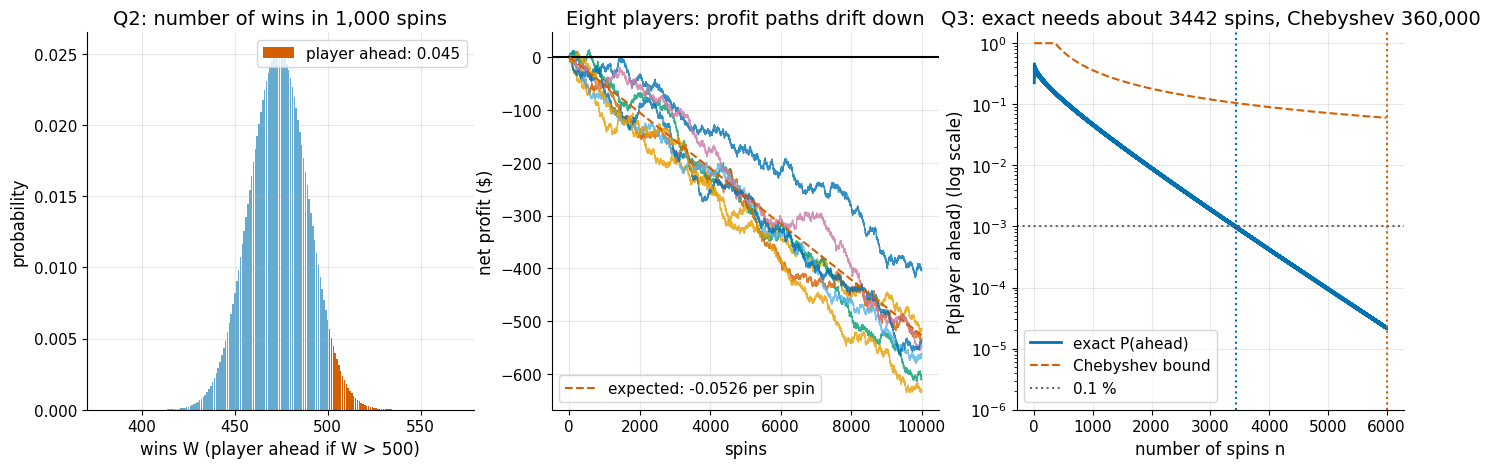

In [17]:
n_curve = np.arange(2, 6001)
exact_curve = np.array([ahead(n) for n in n_curve])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
n_demo = 1000
w = np.arange(380, 570)
axes[0].bar(w, wins(n_demo).pmf(w), color=MAIN, alpha=0.6)
axes[0].bar(w[w > n_demo // 2], wins(n_demo).pmf(w[w > n_demo // 2]), color=HIGHLIGHT, label=f"player ahead: {ahead(n_demo):.3f}")
axes[0].set_title("Q2: number of wins in 1,000 spins")
axes[0].set_xlabel("wins W (player ahead if W > 500)")
axes[0].set_ylabel("probability")
axes[0].legend()
for i in range(8):
    axes[1].plot(np.arange(1, 10001), profit_paths[i], linewidth=1, alpha=0.8)
axes[1].axhline(0, color="black")
x = np.arange(1, 10001)
axes[1].plot(x, mean_profit * x, "--", color=HIGHLIGHT, label="expected: -0.0526 per spin")
axes[1].set_title("Eight players: profit paths drift down")
axes[1].set_xlabel("spins")
axes[1].set_ylabel("net profit ($)")
axes[1].legend()
axes[2].semilogy(n_curve, exact_curve, color=MAIN, linewidth=2, label="exact P(ahead)")
axes[2].semilogy(n_curve, np.minimum(1, sd_profit**2 / (n_curve * mean_profit**2)), "--", color=HIGHLIGHT, label="Chebyshev bound")
axes[2].axhline(0.001, color=NEUTRAL, linestyle=":", label="0.1 %")
axes[2].axvline(n_exact, color=MAIN, linestyle=":")
axes[2].axvline(n_chebyshev if n_chebyshev < 6000 else 6000, color=HIGHLIGHT, linestyle=":")
axes[2].set_ylim(1e-6, 1.5)
axes[2].set_title(f"Q3: exact needs about {n_exact} spins, Chebyshev {n_chebyshev:,}")
axes[2].set_xlabel("number of spins n")
axes[2].set_ylabel("P(player ahead) (log scale)")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
See the printed numbers above. In words:
- Every spin costs the player 5.26 cents on average; the standard deviation of a single spin is almost 1 dollar, so **a single player is quite often ahead** after 100 spins (26.5 %, about one chance in four).
- The LLN works *for the house* because the house takes **all the bets**: after a million spins the casino's expected profit is more than 50 standard deviations above zero, so the casino's result is practically certain.
- **Chebyshev guarantees** the conclusion with no assumptions but asks for about **100 times** more spins (360,000 against about 3,440) than the Normal rule or the exact calculation; it is a safety net, not a forecast.
- **Decision:** a casino can plan on the average (edge times volume) with confidence; a player cannot, for a short session, but the longer they play the less likely they are to be ahead (the exact probability falls toward zero like $e^{-c\,n}$).

---
### Example 2: sizing a poll

**Scenario.** A pollster wants the share of voters supporting a measure to within **±2 percentage points** with **95 % confidence**. Because the true share is unknown, plan for the worst case $p=0.5$ (largest variance). How many people must be surveyed?

**By hand.** $\sigma^2=0.25$, $\varepsilon=0.02$, $\delta=0.05$. *Chebyshev:* $n\ge\frac{0.25}{0.05\cdot0.02^2}=12{,}500$. *Hoeffding* ($b-a=1$): $n\ge\frac{\ln(2/0.05)}{2\cdot0.02^2}=\frac{3.689}{0.0008}\approx4{,}611$. *Normal rule:* $n\ge(1.96\cdot0.5/0.02)^2=2{,}401$. *Exact Binomial:* scan $n$ for $P(|\bar X-0.5|>0.02)\le0.05$.

In [18]:
eps_poll, delta_poll, sigma2 = 0.02, 0.05, 0.25
n_cheb_poll = math.ceil(sigma2 / (delta_poll * eps_poll**2))
n_hoeff_poll = math.ceil(math.log(2 / delta_poll) / (2 * eps_poll**2))
n_norm_poll = math.ceil((1.959964 * 0.5 / eps_poll) ** 2)
n_range = np.arange(100, 6001)
exact_poll = np.array([tail_error_bernoulli(n, eps_poll) for n in n_range])
good = exact_poll <= delta_poll
n_exact_first = int(n_range[np.argmax(good)])                          # first n that works
n_exact_forever = int(n_range[np.max(np.where(~good)[0]) + 1])        # first n after which it always works (up to 6000)
print(f"Chebyshev {n_cheb_poll}, Hoeffding {n_hoeff_poll}, Normal rule {n_norm_poll}, exact: first n that works {n_exact_first}, always works from {n_exact_forever}")
assert n_cheb_poll > n_hoeff_poll > n_norm_poll
assert abs(n_exact_forever - n_norm_poll) < 120

Chebyshev 12500, Hoeffding 4612, Normal rule 2401, exact: first n that works 2375, always works from 2424


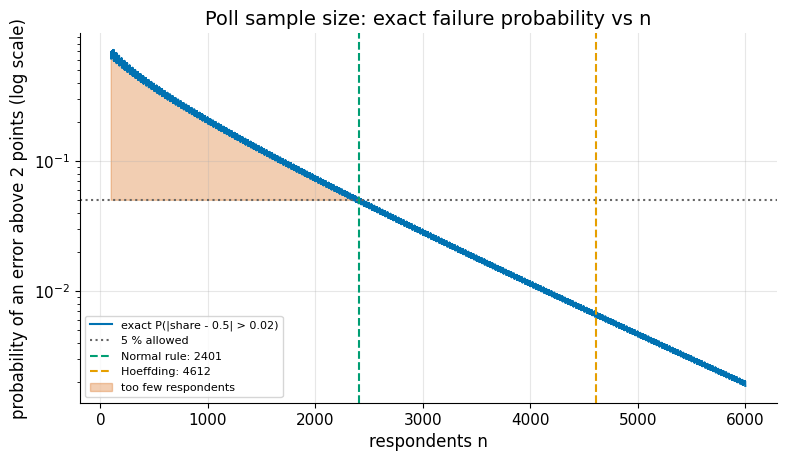

simulation with n = 2401: P(error > 2 points) = 0.0508 (target 0.05)


In [19]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.semilogy(n_range, exact_poll, color=MAIN, label="exact P(|share - 0.5| > 0.02)")
ax.axhline(delta_poll, color=NEUTRAL, linestyle=":", label="5 % allowed")
for value, label, color in [(n_norm_poll, "Normal rule", COLORS[2]), (n_hoeff_poll, "Hoeffding", COLORS[1])]:
    ax.axvline(value, color=color, linestyle="--", label=f"{label}: {value}")
ax.fill_between(n_range, exact_poll, delta_poll, where=exact_poll > delta_poll, color=HIGHLIGHT, alpha=0.3, label="too few respondents")
ax.set_title("Poll sample size: exact failure probability vs n")
ax.set_xlabel("respondents n")
ax.set_ylabel("probability of an error above 2 points (log scale)")
ax.legend(fontsize=8)
plt.show()
sim_poll = np.mean(np.abs(rng.binomial(n_norm_poll, 0.5, 300_000) / n_norm_poll - 0.5) > eps_poll)
print(f"simulation with n = {n_norm_poll}: P(error > 2 points) = {sim_poll:.4f} (target 0.05)")

**Interpretation.** The usual rule of thumb "about **2,400 respondents** give a ±2 point margin" is the Normal rule, and the exact Binomial confirms it (the exact failure probability crosses 5 % close to that sample size and is a little jagged because the Binomial is discrete). **Chebyshev would demand 12,500** (five times more) and Hoeffding about 4,600. If you need a *guarantee* for every distribution, use the bounds; for a normal planning calculation use the Normal rule. **Decision:** survey about 2,400 to 2,500 people; to halve the margin to ±1 point you need **four times** as many (about 9,600), which is the square-root law in action.

---
### Example 3: Monte Carlo estimate of pi and the cost of accuracy

**Scenario.** Throw random points $(U,V)$ uniformly in the unit square. The probability that $U^2+V^2<1$ is the area of the quarter disc, $\pi/4$. So $\hat\pi_n=4\cdot\frac1n\sum\mathbf 1\{U_i^2+V_i^2<1\}$ converges to $\pi$ by the LLN. How accurate is it after $n$ points, and how many points give **3 correct decimals**?

**By hand.** Each indicator is Bernoulli($\pi/4$), so $\sigma_{\hat\pi}=4\sqrt{\frac\pi4(1-\frac\pi4)/n}=1.6422/\sqrt n$. For an error below 0.001 with 95 % confidence: $n\ge(1.96\cdot1.6422/0.001)^2\approx1.04\times10^7$.

In [20]:
true_pi = math.pi
sigma_one = 4 * math.sqrt(true_pi / 4 * (1 - true_pi / 4))
n_needed = math.ceil((1.959964 * sigma_one / 0.001) ** 2)
print(f"standard deviation of one 4*indicator: {sigma_one:.4f}; n for +/-0.001 at 95 %: {n_needed:,}")
assert np.isclose(sigma_one, 1.6422, atol=1e-4)

def estimate_pi(n, generator):
    points = generator.random((n, 2))
    return 4 * np.mean(points[:, 0] ** 2 + points[:, 1] ** 2 < 1)

estimates = {n: [estimate_pi(n, rng) for _ in range(100)] for n in (100, 1000, 10_000, 100_000)}
table = pd.DataFrame({"n": list(estimates), "mean estimate": [np.mean(v) for v in estimates.values()],
                      "sd of estimates": [np.std(v, ddof=1) for v in estimates.values()],
                      "theory sigma/sqrt(n)": [sigma_one / math.sqrt(n) for n in estimates]})
print(table.round(4).to_string(index=False))
assert np.all(np.abs(table["sd of estimates"] / table["theory sigma/sqrt(n)"] - 1) < 0.3)
big = estimate_pi(n_needed, rng)
print(f"one run with n = {n_needed:,}: estimate {big:.5f}, error {big - true_pi:+.5f}")

standard deviation of one 4*indicator: 1.6422; n for +/-0.001 at 95 %: 10,359,517
     n  mean estimate  sd of estimates  theory sigma/sqrt(n)
   100         3.1464           0.1861                0.1642
  1000         3.1484           0.0498                0.0519
 10000         3.1413           0.0166                0.0164
100000         3.1412           0.0054                0.0052


one run with n = 10,359,517: estimate 3.14222, error +0.00062


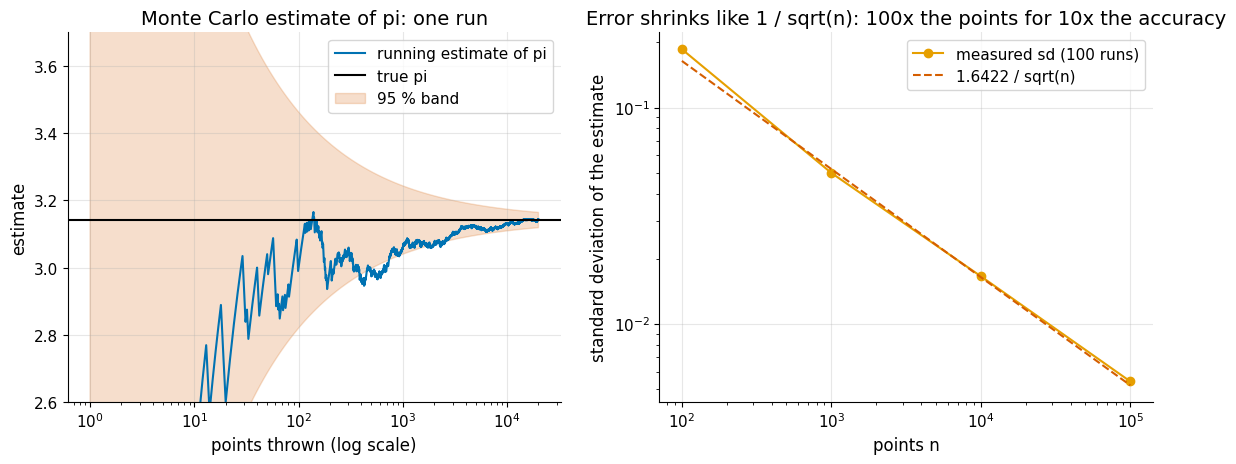

In [21]:
fig, (ax_run, ax_sd) = plt.subplots(1, 2, figsize=(14, 4.8))
pts = rng.random((20000, 2))
inside = pts[:, 0] ** 2 + pts[:, 1] ** 2 < 1
running_pi = 4 * np.cumsum(inside) / np.arange(1, 20001)
ax_run.plot(np.arange(1, 20001), running_pi, color=MAIN, label="running estimate of pi")
ax_run.axhline(math.pi, color="black", label="true pi")
ax_run.fill_between(np.arange(1, 20001), math.pi - 1.96 * sigma_one / np.sqrt(np.arange(1, 20001)), math.pi + 1.96 * sigma_one / np.sqrt(np.arange(1, 20001)), color=HIGHLIGHT, alpha=0.2, label="95 % band")
ax_run.set_xscale("log")
ax_run.set_ylim(2.6, 3.7)
ax_run.set_title("Monte Carlo estimate of pi: one run")
ax_run.set_xlabel("points thrown (log scale)")
ax_run.set_ylabel("estimate")
ax_run.legend()
ax_sd.loglog(table["n"], table["sd of estimates"], "o-", color=SIM, label="measured sd (100 runs)")
ax_sd.loglog(table["n"], table["theory sigma/sqrt(n)"], "--", color=HIGHLIGHT, label="1.6422 / sqrt(n)")
ax_sd.set_title("Error shrinks like 1 / sqrt(n): 100x the points for 10x the accuracy")
ax_sd.set_xlabel("points n")
ax_sd.set_ylabel("standard deviation of the estimate")
ax_sd.legend()
plt.show()

**Interpretation.** The estimate settles on 3.14, but slowly: the standard deviation after 100,000 points is still about 0.005, so only **2 decimals** are reliable. Three correct decimals need about **10 million** points and each extra decimal costs 100 times more. **Decision:** plain Monte Carlo is a poor way to compute $\pi$ (use a series), but it is the right tool when the integral is high-dimensional, where its error rate $1/\sqrt n$ does *not* depend on the dimension; better methods (importance sampling, quasi-Monte Carlo) reduce the constant, not the square-root law. Also remember the pitfall below: this works only because the indicator has a finite mean and variance.

## 12. Where it is used

### Statistics
- **Consistency of estimators:** the sample mean, sample proportion and (via continuity) most method-of-moments and maximum-likelihood estimators are consistent because of the LLN.
- **Frequentist probability and sampling:** polls, quality control and clinical trials rely on averages of many observations, with the sample size chosen from the bounds in 5.3.

### Data science
- **Metrics and A/B tests:** an observed conversion rate converges to the true rate, but only at the $1/\sqrt n$ speed (a small test may mislead).
- **Monte Carlo simulation and bootstrap:** estimating any expectation by an average (Example 3; 05_04); the standard error $\sigma/\sqrt n$ tells how many simulations to run.

### ML and AI
- **Empirical risk minimization:** the training loss (an average over examples) converges to the true expected loss; generalization bounds are Hoeffding-type inequalities.
- **Stochastic gradient descent:** a mini-batch gradient is an average whose noise scales like $1/\sqrt{\text{batch size}}$; reinforcement learning estimates returns by averaging episodes.

## 13. Common pitfalls and misconceptions

- **The gambler's fallacy:** the LLN does **not** say that after a streak of heads tails are "due". Flips are independent; the average converges because new data **dilutes** the early excess, not because it is cancelled (see 7.3: the excess heads keeps growing).
- **"Law of small numbers":** small samples are noisy; 7 heads in 10 flips is not evidence of a biased coin (the standard error at n = 10 is 16 percentage points).
- **The law needs a mean:** for the Cauchy distribution the average never converges (7.4). For heavy tails with infinite variance (Pareto with alpha at most 2) it converges but erratically.
- **Dependence breaks the effective sample size:** 1,000 correlated observations may carry the information of far fewer independent ones.
- **Biased samples do not fix themselves:** the average converges to the mean of the *sampled* population, however large the sample.
- **Chebyshev is a guarantee, not an estimate:** use it when you must be safe for any distribution; use the Normal rule (or the exact distribution) for planning.
- **Convergence in probability is not "every run is close":** the strong law gives it for the whole path, but at any finite $n$ there is still a small chance of a large error.

## 14. Exercises

1. A fair die is rolled $n$ times. Use Chebyshev to find an $n$ guaranteeing $P(|\bar X-3.5|\ge0.1)\le0.05$, and compare it with the Normal-rule value.
2. A factory's defect rate is 2 %. How many items must be inspected so that the observed rate is within ±0.5 percentage points of the true rate with 95 % confidence (Normal rule, and Hoeffding)? Which is smaller, and why?
3. A casino game pays \$1 with probability 0.49 and loses \$1 otherwise. How many bets before the house is 99 % sure to be ahead (Normal rule)? Compare with the roulette answer for the same confidence and comment on the role of the edge.
4. Simulate the running average of Uniform$(0,1)$ draws and of Cauchy draws up to $n=100{,}000$; report the value of each at the end and at $n=1000$ for three seeds each. Which one is stable, and why?
5. Show that $\mathrm{Var}(\bar X_n)=\sigma^2/n$ for independent variables, and explain in one sentence why the sum $S_n$ does not converge while the average does.
6. (Harder) For a Bernoulli($p$) average, find the value of $p$ that makes the required sample size largest for a fixed $\varepsilon$ and $\delta$ (Normal rule), and explain why polls use it.

Solutions are at the end.

## 15. Summary table

| Statement | Formula | Condition | Remark |
|---|---|---|---|
| Weak LLN | P(\|average - mu\| > eps) tends to 0 | finite mean, iid | convergence in probability |
| Strong LLN | average tends to mu with probability 1 | finite mean, iid | whole path converges |
| Standard error | sigma / sqrt(n) | finite variance | halving the error costs 4x the data |
| Chebyshev sample size | n >= sigma^2 / (delta eps^2) | finite variance | safe for any shape, wasteful |
| Hoeffding sample size | n >= (b-a)^2 ln(2/delta) / (2 eps^2) | bounded values | grows only like ln(1/delta) |
| Normal rule sample size | n = (z sigma / eps)^2 | large n | tightest, approximate |
| Failure | average of Cauchy is Cauchy | no mean | no convergence |

## Solutions

In [22]:
var_die = 35 / 12
n1_cheb = np.ceil(var_die / (0.05 * 0.1**2))
n1_norm = np.ceil((stats.norm.isf(0.025) * np.sqrt(var_die) / 0.1) ** 2)
print("1: Chebyshev n =", int(n1_cheb), " Normal rule n =", int(n1_norm))
p_def = 0.02
n2_norm = np.ceil((stats.norm.isf(0.025) * np.sqrt(p_def * (1 - p_def)) / 0.005) ** 2)
n2_hoeff = np.ceil(np.log(2 / 0.05) / (2 * 0.005**2))
print("2: Normal rule n =", int(n2_norm), " Hoeffding n =", int(n2_hoeff), "(Hoeffding ignores that p is small: it assumes the worst variance 0.25)")
mu3, sd3 = 2 * 0.49 - 1, np.sqrt(1 - (2 * 0.49 - 1) ** 2)
n3 = np.ceil((stats.norm.isf(0.01) * sd3 / abs(mu3)) ** 2)
n3_roulette = np.ceil((stats.norm.isf(0.01) * sd_profit / abs(mean_profit)) ** 2)
print("3: house edge 2 %: n =", int(n3), " roulette (edge 5.26 %): n =", int(n3_roulette), " ratio ~", round(n3 / n3_roulette, 2), "(n scales like 1/edge^2)")
local = np.random.default_rng(7)
for name, gen in (("Uniform", lambda k: local.uniform(0, 1, k)), ("Cauchy", lambda k: local.standard_cauchy(k))):
    out = []
    for seed in range(3):
        x = gen(100_000)
        out.append((round(float(x[:1000].mean()), 3), round(float(x.mean()), 3)))
    print("4:", name, "(mean at n = 1000, mean at n = 100000) for three runs:", out)
print("6: required n is proportional to p (1 - p), largest at p = 0.5:", [round(p * (1 - p), 3) for p in (0.1, 0.3, 0.5, 0.7)])

1: Chebyshev n = 5834  Normal rule n = 1121
2: Normal rule n = 3012  Hoeffding n = 73778 (Hoeffding ignores that p is small: it assumes the worst variance 0.25)
3: house edge 2 %: n = 13525  roulette (edge 5.26 %): n = 1949  ratio ~ 6.94 (n scales like 1/edge^2)
4: Uniform (mean at n = 1000, mean at n = 100000) for three runs: [(0.494, 0.5), (0.499, 0.501), (0.498, 0.5)]
4: Cauchy (mean at n = 1000, mean at n = 100000) for three runs: [(-0.442, -1.744), (-2.103, 1.589), (1.193, 1.466)]
6: required n is proportional to p (1 - p), largest at p = 0.5: [0.09, 0.21, 0.25, 0.21]


**1.** Chebyshev needs $n\ge\frac{35/12}{0.05\cdot0.01}\approx5{,}834$; the Normal rule asks for about 1,121 (printed above): the guarantee costs five times more.

**2.** The Normal rule uses the real variance $0.02\cdot0.98$ and needs about 3,010 items; Hoeffding assumes the worst case (variance 0.25) and needs about 73,778. For a rare defect the Normal rule is much cheaper, but Hoeffding holds for any $p$.

**3.** With edge 2 % the number of bets for 99 % confidence is about 13,500, versus about 1,950 for roulette's 5.26 % edge: the required $n$ scales like $1/\text{edge}^2$, so a casino with a smaller edge needs about seven times more bets to be as sure.

**4.** Uniform averages are nearly identical across runs (about 0.5 at both sizes); Cauchy averages jump around by order 1 at every size and do not improve with $n$, because the Cauchy has no mean.

**5.** $\mathrm{Var}(\sum X_i)=n\sigma^2$ by independence and $\mathrm{Var}(c\,Y)=c^2\mathrm{Var}(Y)$ with $c=1/n$ gives $\sigma^2/n$. The sum's spread grows like $\sqrt n$ (it has nothing to settle on); the average divides it by $n$.

**6.** The variance $p(1-p)$ is largest at $p=0.5$, so the worst-case sample size is at $p=0.5$; pollsters plan with that value so the survey is large enough whatever the true share is.